Kullanılan cihaz: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 36.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.20MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.56MB/s]


Epoch [1/10] | Train Loss: 0.3720, Train Acc: 88.71% | Val Loss: 0.2604, Val Acc: 92.02%
Epoch [2/10] | Train Loss: 0.1655, Train Acc: 94.84% | Val Loss: 0.1751, Val Acc: 94.83%
Epoch [3/10] | Train Loss: 0.1233, Train Acc: 96.10% | Val Loss: 0.1459, Val Acc: 95.60%
Epoch [4/10] | Train Loss: 0.0980, Train Acc: 96.96% | Val Loss: 0.1329, Val Acc: 95.76%
Epoch [5/10] | Train Loss: 0.0816, Train Acc: 97.47% | Val Loss: 0.1287, Val Acc: 96.05%
Epoch [6/10] | Train Loss: 0.0701, Train Acc: 97.75% | Val Loss: 0.0972, Val Acc: 97.25%
Epoch [7/10] | Train Loss: 0.0624, Train Acc: 97.95% | Val Loss: 0.1021, Val Acc: 97.09%
Epoch [8/10] | Train Loss: 0.0529, Train Acc: 98.23% | Val Loss: 0.1023, Val Acc: 97.24%
Epoch [9/10] | Train Loss: 0.0499, Train Acc: 98.32% | Val Loss: 0.0965, Val Acc: 97.44%
Epoch [10/10] | Train Loss: 0.0451, Train Acc: 98.53% | Val Loss: 0.1053, Val Acc: 97.14%

Toplam Eğitim Süresi: 195.21 saniye
Test Doğruluk Oranı (Test Accuracy): 97.09%


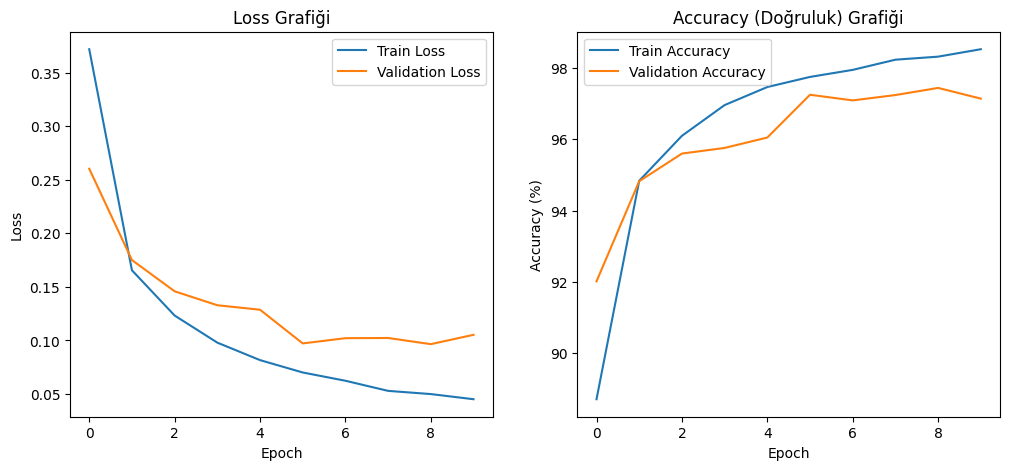

Eğitim grafikleri 'egitim_grafikleri.png' olarak kaydedildi.


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import time
from PIL import Image
import os

# 1. Cihaz Ayarı (GPU varsa hızlanır)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Kullanılan cihaz: {device}")

# 2. Veri Dönüşümleri ve MNIST Yüklenmesi
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

full_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Train (%80) ve Validation (%20) Ayrımı
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# 3. MLP Modeli (En az 2 Hidden Layer)
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 256)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(256, 128)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)
        return x

model = MLP().to(device)

# 4. Loss ve Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 5. Eğitim ve Doğrulama (Training & Validation) Döngüsü
epochs = 10
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

start_time = time.time()

for epoch in range(epochs):
    # --- EĞİTİM ---
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_train_loss = running_loss / len(train_dataset)
    epoch_train_acc = 100. * correct / total
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # --- VALIDATION ---
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    epoch_val_loss = val_loss / len(val_dataset)
    epoch_val_acc = 100. * val_correct / val_total
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}%")

end_time = time.time()
print(f"\nToplam Eğitim Süresi: {end_time - start_time:.2f} saniye")

# 6. Test Verisi ile Final Değerlendirmesi
model.eval()
test_correct = 0
test_total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        test_total += labels.size(0)
        test_correct += predicted.eq(labels).sum().item()

test_acc = 100. * test_correct / test_total
print(f"Test Doğruluk Oranı (Test Accuracy): {test_acc:.2f}%")

# 7. Grafiklerin Çizdirilmesi ve Kaydedilmesi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss Grafiği')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Accuracy (Doğruluk) Grafiği')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.savefig('egitim_grafikleri.png')
plt.show()
print("Eğitim grafikleri 'egitim_grafikleri.png' olarak kaydedildi.")

In [11]:
import os
import time
import glob
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# 1. Cihaz Ayarı
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Kullanılan cihaz: {device}")

# 2. Hiperparametreler
BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 10

# 3. Veri Ön İşleme ve MNIST Yükleme
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Train (%80) ve Validation (%20) Ayrımı
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 4. MLP Modeli (En az 2 Hidden Layer, ReLU)
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 256)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(256, 128)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)
        return x

model = MLP().to(device)

# 5. Loss ve Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# 6. Model Eğitimi (Training & Validation)
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

print("\nModel Eğitimi Başlıyor...")
start_time = time.time()

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_train_loss = running_loss / len(train_dataset)
    epoch_train_acc = 100. * correct / total
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    epoch_val_loss = val_loss / len(val_dataset)
    epoch_val_acc = 100. * val_correct / val_total
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}%")

total_training_time = time.time() - start_time
print(f"\nToplam Eğitim Süresi: {total_training_time:.2f} saniye")

# 7. Test Değerlendirmesi
model.eval()
test_correct = 0
test_total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        test_total += labels.size(0)
        test_correct += predicted.eq(labels).sum().item()

test_acc = 100. * test_correct / test_total
print(f"Final Test Doğruluk Oranı (Test Accuracy): {test_acc:.2f}%\n")

# 8. Kendi El Yazısı Rakamlarını Otomatik Test Etme Bölümü
os.chdir('/content')
# 'rakam_' ile başlayan tüm dosyaları otomatik yakalar (isim uzantısı ne olursa olsun)
el_yazisi_dosyalari = sorted([f for f in glob.glob('rakam_*') if not f.endswith('.ipynb')])

print(f"Bulunan el yazısı dosyaları: {el_yazisi_dosyalari}\n")
print("--- Kendi El Yazısı Rakam Testi Sonuçları ---")

for dosya in el_yazisi_dosyalari:
    try:
        img = Image.open(dosya).convert('L')
        img = ImageOps.invert(img) # Beyaz zemin / siyah yazıyı ters çevirir
        img = img.resize((28, 28))

        transform_inf = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])

        img_tensor = transform_inf(img).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            output = model(img_tensor)
            probabilities = nn.functional.softmax(output, dim=1)
            confidence, predicted = torch.max(probabilities, 1)

        print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
    except Exception as e:
        print(f"'{dosya}' işlenirken hata oluştu: {e}")

Kullanılan cihaz: cpu

Model Eğitimi Başlıyor...
Epoch [1/10] | Train Loss: 0.2558, Train Acc: 92.34% | Val Loss: 0.1361, Val Acc: 95.69%
Epoch [2/10] | Train Loss: 0.1027, Train Acc: 96.84% | Val Loss: 0.1071, Val Acc: 96.80%
Epoch [3/10] | Train Loss: 0.0697, Train Acc: 97.76% | Val Loss: 0.1110, Val Acc: 96.72%
Epoch [4/10] | Train Loss: 0.0542, Train Acc: 98.24% | Val Loss: 0.1033, Val Acc: 96.97%
Epoch [5/10] | Train Loss: 0.0426, Train Acc: 98.60% | Val Loss: 0.1055, Val Acc: 97.26%
Epoch [6/10] | Train Loss: 0.0324, Train Acc: 98.90% | Val Loss: 0.0954, Val Acc: 97.43%
Epoch [7/10] | Train Loss: 0.0286, Train Acc: 99.03% | Val Loss: 0.1012, Val Acc: 97.84%
Epoch [8/10] | Train Loss: 0.0235, Train Acc: 99.17% | Val Loss: 0.1215, Val Acc: 97.21%
Epoch [9/10] | Train Loss: 0.0215, Train Acc: 99.24% | Val Loss: 0.1136, Val Acc: 97.44%
Epoch [10/10] | Train Loss: 0.0190, Train Acc: 99.37% | Val Loss: 0.1121, Val Acc: 97.59%

Toplam Eğitim Süresi: 182.87 saniye
Final Test Doğruluk Ora

In [15]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# 1. Cihaz Ayarı
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Kullanılan cihaz: {device}")

# 2. Hiperparametreler
BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 10

# 3. Veri Ön İşleme ve MNIST Yükleme
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Train (%80) ve Validation (%20) Ayrımı
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 4. MLP Modeli (En az 2 Hidden Layer, ReLU)
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 256)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(256, 128)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)
        return x

model = MLP().to(device)

# 5. Loss ve Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# 6. Model Eğitimi (Training & Validation)
print("\nModel Eğitimi Başlıyor...")
start_time = time.time()

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_train_loss = running_loss / len(train_dataset)
    epoch_train_acc = 100. * correct / total

    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    epoch_val_loss = val_loss / len(val_dataset)
    epoch_val_acc = 100. * val_correct / val_total

    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}%")

print(f"\nToplam Eğitim Süresi: {time.time() - start_time:.2f} saniye")

# 7. Test Değerlendirmesi
model.eval()
test_correct = 0
test_total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        test_total += labels.size(0)
        test_correct += predicted.eq(labels).sum().item()

print(f"Final Test Doğruluk Oranı (Test Accuracy): {100. * test_correct / test_total:.2f}%\n")

# 8. Kendi El Yazısı Rakamlarını Test Etme Bölümü
os.chdir('/content')
# Dosya adlarını kendine göre buraya yazabilirsin (Örn: rakam_1.png, rakam_2.png ...)
el_yazisi_dosyalari = ['rakam_1.png', 'rakam_2.png', 'rakam_3.png', 'rakam_4.png', 'rakam_5.png', 'rakam_6.png', 'rakam_7.png']

print("--- Kendi El Yazısı Rakam Testi Sonuçları ---")
for dosya in el_yazisi_dosyalari:
    try:
        img = Image.open(dosya).convert('L')
        img = ImageOps.invert(img) # Siyah zemin / beyaz yazıya çevirir
        img = img.resize((28, 28))

        transform_inf = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])

        img_tensor = transform_inf(img).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            output = model(img_tensor)
            probabilities = nn.functional.softmax(output, dim=1)
            confidence, predicted = torch.max(probabilities, 1)

        print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
    except Exception as e:
        print(f"'{dosya}' okunurken hata oluştu: {e}")

Kullanılan cihaz: cpu

Model Eğitimi Başlıyor...
Epoch [1/10] | Train Loss: 0.2561, Train Acc: 92.22% | Val Loss: 0.1263, Val Acc: 95.85%
Epoch [2/10] | Train Loss: 0.1043, Train Acc: 96.79% | Val Loss: 0.0949, Val Acc: 97.12%
Epoch [3/10] | Train Loss: 0.0721, Train Acc: 97.79% | Val Loss: 0.0953, Val Acc: 96.75%
Epoch [4/10] | Train Loss: 0.0526, Train Acc: 98.35% | Val Loss: 0.0913, Val Acc: 97.19%
Epoch [5/10] | Train Loss: 0.0424, Train Acc: 98.62% | Val Loss: 0.0914, Val Acc: 97.38%
Epoch [6/10] | Train Loss: 0.0352, Train Acc: 98.79% | Val Loss: 0.0769, Val Acc: 97.81%
Epoch [7/10] | Train Loss: 0.0285, Train Acc: 99.06% | Val Loss: 0.0989, Val Acc: 97.29%
Epoch [8/10] | Train Loss: 0.0268, Train Acc: 99.12% | Val Loss: 0.0879, Val Acc: 97.77%
Epoch [9/10] | Train Loss: 0.0219, Train Acc: 99.28% | Val Loss: 0.0974, Val Acc: 97.52%
Epoch [10/10] | Train Loss: 0.0203, Train Acc: 99.33% | Val Loss: 0.1070, Val Acc: 97.57%

Toplam Eğitim Süresi: 181.39 saniye
Final Test Doğruluk Ora

In [17]:
import glob
from PIL import Image, ImageOps
import torch
import torchvision.transforms as transforms

# Bulunduğumuz dizindeki tüm resim dosyalarını otomatik bul
bulunan_dosyalar = sorted([f for f in glob.glob('*') if f.lower().endswith(('.png', '.jpg', '.jpeg')) and 'rakam' in f.lower()])

print(f"Bulunan el yazısı dosyaları: {bulunan_dosyalar}\n")
print("--- Kendi El Yazısı Rakam Testi Sonuçları ---")

for dosya in bulunan_dosyalar:
    try:
        img = Image.open(dosya).convert('L')
        img = ImageOps.invert(img) # Beyaz kağıt / siyah yazı için renkleri ters çevir
        img = img.resize((28, 28))

        transform_inf = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])

        img_tensor = transform_inf(img).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            output = model(img_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence, predicted = torch.max(probabilities, 1)

        print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
    except Exception as e:
        print(f"'{dosya}' işlenirken hata oluştu: {e}")

Bulunan el yazısı dosyaları: []

--- Kendi El Yazısı Rakam Testi Sonuçları ---


In [18]:
from PIL import Image, ImageOps
import torch
import torchvision.transforms as transforms

# Sol panelde gördüğün tam dosya adlarını buraya yazdık
el_yazisi_dosyalari = [
    'rakam_1.png.jpeg', 'rakam_2.png.jpeg', 'rakam_3.png.jpeg',
    'rakam_4.png.jpeg', 'rakam_5.png.jpeg', 'rakam_6.png.jpeg', 'rakam_7.png.jpeg'
]

print("--- Kendi El Yazısı Rakam Testi Sonuçları ---\n")

for dosya in el_yazisi_dosyalari:
    try:
        img = Image.open(dosya).convert('L')
        img = ImageOps.invert(img) # Beyaz kağıt / siyah yazı için renkleri ters çevirir
        img = img.resize((28, 28))

        transform_inf = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])

        img_tensor = transform_inf(img).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            output = model(img_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence, predicted = torch.max(probabilities, 1)

        print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
    except Exception as e:
        print(f"'{dosya}' okunurken hata oluştu: {e}")

--- Kendi El Yazısı Rakam Testi Sonuçları ---

'rakam_1.png.jpeg' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_1.png.jpeg'
'rakam_2.png.jpeg' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_2.png.jpeg'
'rakam_3.png.jpeg' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_3.png.jpeg'
'rakam_4.png.jpeg' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_4.png.jpeg'
'rakam_5.png.jpeg' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_5.png.jpeg'
'rakam_6.png.jpeg' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_6.png.jpeg'
'rakam_7.png.jpeg' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_7.png.jpeg'


In [19]:
from PIL import Image, ImageOps
import torch
import torchvision.transforms as transforms

# Tertemiz ve kısa dosya adları
el_yazisi_dosyalari = [
    'rakam_1.png', 'rakam_2.png', 'rakam_3.png',
    'rakam_4.png', 'rakam_5.png', 'rakam_6.png', 'rakam_7.png'
]

print("--- Kendi El Yazısı Rakam Testi Sonuçları ---\n")

for dosya in el_yazisi_dosyalari:
    try:
        img = Image.open(dosya).convert('L')
        img = ImageOps.invert(img)  # Beyaz zemin / siyah yazıyı ters çevirir
        img = img.resize((28, 28))

        transform_inf = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])

        img_tensor = transform_inf(img).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            output = model(img_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence, predicted = torch.max(probabilities, 1)

        print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
    except Exception as e:
        print(f"'{dosya}' okunurken hata oluştu: {e}")

--- Kendi El Yazısı Rakam Testi Sonuçları ---

'rakam_1.png' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_1.png'
'rakam_2.png' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_2.png'
'rakam_3.png' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_3.png'
'rakam_4.png' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_4.png'
'rakam_5.png' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_5.png'
'rakam_6.png' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_6.png'
'rakam_7.png' okunurken hata oluştu: [Errno 2] No such file or directory: 'rakam_7.png'


In [20]:
import os
from PIL import Image, ImageOps
import torch
import torchvision.transforms as transforms

# Çalışma dizinini kesin olarak /content yapıyoruz
os.chdir('/content')

# Test edilecek dosya listesi
el_yazisi_dosyalari = [
    'rakam_1.png', 'rakam_2.png', 'rakam_3.png',
    'rakam_4.png', 'rakam_5.png', 'rakam_6.png',
    'rakam_7.png', 'rakam_8.png', 'rakam_9.png',
    'rakam_10.png', 'rakam_11.png'
]

print("--- Kendi El Yazısı Rakam Testi Sonuçları ---\n")

for dosya in el_yazisi_dosyalari:
    tam_yol = os.path.join('/content', dosya)
    try:
        img = Image.open(tam_yol).convert('L')
        img = ImageOps.invert(img)  # Beyaz zemin / siyah yazıyı ters çevirir
        img = img.resize((28, 28))

        transform_inf = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])

        img_tensor = transform_inf(img).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            output = model(img_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence, predicted = torch.max(probabilities, 1)

        print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
    except Exception as e:
        print(f"'{dosya}' okunurken hata oluştu: {e}")

--- Kendi El Yazısı Rakam Testi Sonuçları ---

'rakam_1.png' okunurken hata oluştu: [Errno 2] No such file or directory: '/content/rakam_1.png'
'rakam_2.png' okunurken hata oluştu: [Errno 2] No such file or directory: '/content/rakam_2.png'
'rakam_3.png' okunurken hata oluştu: [Errno 2] No such file or directory: '/content/rakam_3.png'
'rakam_4.png' okunurken hata oluştu: [Errno 2] No such file or directory: '/content/rakam_4.png'
'rakam_5.png' okunurken hata oluştu: [Errno 2] No such file or directory: '/content/rakam_5.png'
'rakam_6.png' okunurken hata oluştu: [Errno 2] No such file or directory: '/content/rakam_6.png'
'rakam_7.png' okunurken hata oluştu: [Errno 2] No such file or directory: '/content/rakam_7.png'
'rakam_8.png' okunurken hata oluştu: [Errno 2] No such file or directory: '/content/rakam_8.png'
'rakam_9.png' okunurken hata oluştu: [Errno 2] No such file or directory: '/content/rakam_9.png'
'rakam_10.png' okunurken hata oluştu: [Errno 2] No such file or directory: '/con

In [21]:
import os
print("Şu anki çalışma dizini:", os.getcwd())
print("Bu dizindeki dosyalar:", os.listdir('.'))

Şu anki çalışma dizini: /content
Bu dizindeki dosyalar: ['.config', 'data', 'egitim_grafikleri.png', 'sample_data']


In [22]:
import glob
from PIL import Image, ImageOps
import torch
import torchvision.transforms as transforms

# Uzantısına bakılmaksızın 'rakam_' ile başlayan tüm dosyaları doğrudan buluruz
el_yazisi_dosyalari = sorted(glob.glob('rakam_*'))

print(f"Bulunan dosyalar: {el_yazisi_dosyalari}\n")
print("--- Kendi El Yazısı Rakam Testi Sonuçları ---")

for dosya in el_yazisi_dosyalari:
    try:
        img = Image.open(dosya).convert('L')
        img = ImageOps.invert(img)  # Beyaz kağıt / siyah yazı için renkleri ters çevirir
        img = img.resize((28, 28))

        transform_inf = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])

        img_tensor = transform_inf(img).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            output = model(img_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence, predicted = torch.max(probabilities, 1)

        print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
    except Exception as e:
        print(f"'{dosya}' okunurken hata oluştu: {e}")

Bulunan dosyalar: []

--- Kendi El Yazısı Rakam Testi Sonuçları ---


In [23]:
import glob
import os
from PIL import Image, ImageOps
import torch
import torchvision.transforms as transforms

# /content dizinindeki rakam ile başlayan tüm dosyaları uzantı fark etmeksizin bul
os.chdir('/content')
bulunan_dosyalar = sorted(glob.glob('rakam_*'))

print(f"Bulunan dosyalar: {bulunan_dosyalar}\n")
print("--- Kendi El Yazısı Rakam Testi Sonuçları ---")

for dosya in bulunan_dosyalar:
    # Sadece geçerli resim dosyalarını işleme al
    if dosya.lower().endswith(('.png', '.jpeg', '.jpg', '.png.jpeg')):
        try:
            img = Image.open(dosya).convert('L')
            img = ImageOps.invert(img)  # Beyaz zemin / siyah yazı uyarlaması
            img = img.resize((28, 28))

            transform_inf = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize((0.1307,), (0.3081,))
            ])

            img_tensor = transform_inf(img).unsqueeze(0).to(device)

            model.eval()
            with torch.no_grad():
                output = model(img_tensor)
                probabilities = torch.nn.functional.softmax(output, dim=1)
                confidence, predicted = torch.max(probabilities, 1)

            print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
        except Exception as e:
            print(f"'{dosya}' işlenirken hata oluştu: {e}")

Bulunan dosyalar: []

--- Kendi El Yazısı Rakam Testi Sonuçları ---


In [24]:
import os
from PIL import Image, ImageOps
import torch
import torchvision.transforms as transforms

# /content dizinindeki tüm dosyaları listele
dosyalar = os.listdir('/content')
print("Bulunan tüm dosyalar:", dosyalar)
print("-" * 40)

# Sadece resim olanları seç ve test et
for dosya in dosyalar:
    if dosya.lower().endswith(('.png', '.jpg', '.jpeg', '.png.jpeg', '.jpg.jpeg')):
        try:
            img = Image.open(dosya).convert('L')
            img = ImageOps.invert(img)  # Beyaz zemin / siyah yazı uyarlaması
            img = img.resize((28, 28))

            transform_inf = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize((0.1307,), (0.3081,))
            ])

            img_tensor = transform_inf(img).unsqueeze(0).to(device)

            model.eval()
            with torch.no_grad():
                output = model(img_tensor)
                probabilities = torch.nn.functional.softmax(output, dim=1)
                confidence, predicted = torch.max(probabilities, 1)

            print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
        except Exception as e:
            print(f"'{dosya}' işlenirken hata oluştu: {e}")

Bulunan tüm dosyalar: ['.config', 'data', 'egitim_grafikleri.png', 'sample_data']
----------------------------------------
Dosya: egitim_grafikleri.png --> Modelin Tahmini: 5 (Güven Oranı: %99.67)


In [25]:
import os
from PIL import Image, ImageOps
import torch
import torchvision.transforms as transforms

# /content dizinindeki tüm dosyaları listele
dosyalar = os.listdir('/content')
print("Bulunan tüm dosyalar:", dosyalar)
print("-" * 40)

# Sadece resim olanları seç ve test et
for dosya in dosyalar:
    if dosya.lower().endswith(('.png', '.jpg', '.jpeg', '.png.jpeg', '.jpg.jpeg')):
        try:
            dosya_yolu = os.path.join('/content', dosya)
            img = Image.open(dosya_yolu).convert('L')
            img = ImageOps.invert(img)  # Beyaz zemin / siyah yazı uyarlaması
            img = img.resize((28, 28))

            transform_inf = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize((0.1307,), (0.3081,))
            ])

            img_tensor = transform_inf(img).unsqueeze(0).to(device)

            model.eval()
            with torch.no_grad():
                output = model(img_tensor)
                probabilities = torch.nn.functional.softmax(output, dim=1)
                confidence, predicted = torch.max(probabilities, 1)

            print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
        except Exception as e:
            print(f"'{dosya}' işlenirken hata oluştu: {e}")

Bulunan tüm dosyalar: ['.config', 'data', 'egitim_grafikleri.png', 'sample_data']
----------------------------------------
Dosya: egitim_grafikleri.png --> Modelin Tahmini: 5 (Güven Oranı: %99.67)


In [26]:
import glob
import os
from PIL import Image, ImageOps
import torch
import torchvision.transforms as transforms

# /content altındaki tüm klasörlerde recursive (özyinelemeli) olarak rakam dosyalarını ara
bulunan_dosyalar = glob.glob('/content/**/rakam_*', recursive=True)
print(f"Bulunan dosya yolları: {bulunan_dosyalar}")
print("-" * 50)

for dosya_yolu in bulunan_dosyalar:
    # Resim uzantısına sahip olanları işleme al
    if dosya_yolu.lower().endswith(('.png', '.jpg', '.jpeg', '.png.jpeg', '.jpg.jpeg')):
        try:
            img = Image.open(dosya_yolu).convert('L')
            img = ImageOps.invert(img)  # Beyaz zemin / siyah yazı uyarlaması
            img = img.resize((28, 28))

            transform_inf = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize((0.1307,), (0.3081,))
            ])

            img_tensor = transform_inf(img).unsqueeze(0).to(device)

            model.eval()
            with torch.no_grad():
                output = model(img_tensor)
                probabilities = torch.nn.functional.softmax(output, dim=1)
                confidence, predicted = torch.max(probabilities, 1)

            dosya_adi = os.path.basename(dosya_yolu)
            print(f"Dosya: {dosya_adi} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
        except Exception as e:
            print(f"'{dosya_yolu}' işlenirken hata oluştu: {e}")

Bulunan dosya yolları: []
--------------------------------------------------


In [27]:
from google.colab import files
from PIL import Image, ImageOps
import torch
import torchvision.transforms as transforms

print("Lütfen bilgisayarındaki el yazısı rakam resimlerini (rakam_1.png, rakam_2.png vb.) seç ve yükle:")
uploaded = files.upload()

print("\n--- Kendi El Yazısı Rakam Testi Sonuçları ---")
for dosya in uploaded.keys():
    try:
        img = Image.open(dosya).convert('L')
        img = ImageOps.invert(img)  # Beyaz zemin / siyah yazı uyarlaması
        img = img.resize((28, 28))

        transform_inf = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])

        img_tensor = transform_inf(img).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            output = model(img_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence, predicted = torch.max(probabilities, 1)

        print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
    except Exception as e:
        print(f"'{dosya}' işlenirken hata oluştu: {e}")

Lütfen bilgisayarındaki el yazısı rakam resimlerini (rakam_1.png, rakam_2.png vb.) seç ve yükle:


Saving rakam_11.png.jpeg to rakam_11.png.jpeg
Saving rakam_10.png.jpeg to rakam_10.png.jpeg
Saving rakam_9.png.jpeg to rakam_9.png.jpeg
Saving rakam_8.png.jpeg to rakam_8.png.jpeg
Saving rakam_7.png.jpeg to rakam_7.png.jpeg
Saving rakam_6.png.jpeg to rakam_6.png.jpeg
Saving rakam_5.png.jpeg to rakam_5.png.jpeg
Saving rakam_4.png.jpeg to rakam_4.png.jpeg
Saving rakam_3.png.jpeg to rakam_3.png.jpeg
Saving rakam_2.png.jpeg to rakam_2.png.jpeg
Saving rakam_1.png.jpeg to rakam_1.png.jpeg

--- Kendi El Yazısı Rakam Testi Sonuçları ---
Dosya: rakam_11.png.jpeg --> Modelin Tahmini: 3 (Güven Oranı: %99.99)
Dosya: rakam_10.png.jpeg --> Modelin Tahmini: 3 (Güven Oranı: %100.00)
Dosya: rakam_9.png.jpeg --> Modelin Tahmini: 3 (Güven Oranı: %100.00)
Dosya: rakam_8.png.jpeg --> Modelin Tahmini: 3 (Güven Oranı: %100.00)
Dosya: rakam_7.png.jpeg --> Modelin Tahmini: 3 (Güven Oranı: %99.95)
Dosya: rakam_6.png.jpeg --> Modelin Tahmini: 3 (Güven Oranı: %100.00)
Dosya: rakam_5.png.jpeg --> Modelin Tahmini: 

In [28]:
from PIL import Image
import torch
import torchvision.transforms as transforms

print("--- Güncellenmiş El Yazısı Rakam Testi Sonuçları ---")
for dosya in uploaded.keys():
    try:
        img = Image.open(dosya).convert('L')
        # Invert (renk ters çevirme) satırını kaldırdık, gerekirse deneriz
        img = img.resize((28, 28))

        transform_inf = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])

        img_tensor = transform_inf(img).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            output = model(img_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence, predicted = torch.max(probabilities, 1)

        print(f"Dosya: {dosya} --> Modelin Tahmini: {predicted.item()} (Güven Oranı: %{confidence.item()*100:.2f})")
    except Exception as e:
        print(f"'{dosya}' işlenirken hata oluştu: {e}")

--- Güncellenmiş El Yazısı Rakam Testi Sonuçları ---
Dosya: rakam_11.png.jpeg --> Modelin Tahmini: 7 (Güven Oranı: %84.18)
Dosya: rakam_10.png.jpeg --> Modelin Tahmini: 3 (Güven Oranı: %91.73)
Dosya: rakam_9.png.jpeg --> Modelin Tahmini: 7 (Güven Oranı: %93.48)
Dosya: rakam_8.png.jpeg --> Modelin Tahmini: 2 (Güven Oranı: %50.65)
Dosya: rakam_7.png.jpeg --> Modelin Tahmini: 3 (Güven Oranı: %99.97)
Dosya: rakam_6.png.jpeg --> Modelin Tahmini: 5 (Güven Oranı: %83.22)
Dosya: rakam_5.png.jpeg --> Modelin Tahmini: 3 (Güven Oranı: %86.75)
Dosya: rakam_4.png.jpeg --> Modelin Tahmini: 2 (Güven Oranı: %99.02)
Dosya: rakam_3.png.jpeg --> Modelin Tahmini: 2 (Güven Oranı: %83.69)
Dosya: rakam_2.png.jpeg --> Modelin Tahmini: 3 (Güven Oranı: %99.99)
Dosya: rakam_1.png.jpeg --> Modelin Tahmini: 3 (Güven Oranı: %82.02)
